<a href="https://colab.research.google.com/github/santiagoleguizamon10/TP-labo/blob/fran_pando/NuevomodeloRol3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Influencia de la Localía en el Control del Juego y la Posesión**

¿Existe una influencia estadísticamente significativa de la localía sobre el porcentaje de posesión del balón, o la tenencia responde a la identidad táctica de los equipos al margen del estadio?

En el fútbol se asume que jugar en el propio estadio genera una presión ambiental y territorial que impele al equipo local a tomar el protagonismo del partido. Evaluar esta variable permite cuantificar si la localía altera la tenencia del balón o si es una dimensión neutra ante el modelo de juego de cada club.

In [1]:
# ==============================================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y CARGA DEL DATASET --------- PASO A ELIMINAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL ------------
# ==============================================================================
# Justificación: Establece el entorno reproducible en Google Colab e inspecciona
# las variables de posesión de balón y condición de localía.
# Logro: Carga en memoria del DataFrame y verificación de las 194 observaciones.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

url = 'https://raw.githubusercontent.com/santiagoleguizamon10/TP-labo/main/data/Clausura26_tp_labo.csv'
df = pd.read_csv(url)

print("Dimensiones del dataset:", df.shape)
df.head(3)

Dimensiones del dataset: (194, 21)


,Fecha,Local,Visitante,Resultado (L),Resultado (V),Posesión de balón (L),Posesión de balón (V),Goles esperados (xG) (L),Goles esperados (xG) (V),Tiros totales (L),...,Tiros al arco (L),Tiros al arco (V),Córners (L),Córners (V),Faltas (L),Faltas (V),Tarjetas amarillas (L),Tarjetas amarillas (V),Tarjetas rojas (L),Tarjetas rojas (V)
0,Fecha 1,Club Atlético Belgrano,Rosario Central,2,1,48%,52%,1.50,1.39,13,...,5,3,6,6,10,13,0.0,2.0,0,0
1,Fecha 1,Sarmiento,Argentinos Juniors,2,3,45%,55%,1.50,1.42,12,...,3,5,7,2,15,14,3.0,6.0,0,1
2,Fecha 1,Defensa y Justicia,Aldosivi,1,1,72%,28%,1.06,0.59,15,...,5,3,6,2,9,15,2.0,3.0,0,0


In [2]:
# ==============================================================================
# PASO 2: LIMPIEZA DE DATOS Y CONSTRUCCIÓN DE LA BRECHA TERRITORIAL ------- PASO A REESTRUCTURAR A LA HORA DE JUNTAR CON EL TRABAJO PRINCIPAL -------
# ==============================================================================
# Justificación: Convierte la posesión de texto (%) a flotante numérico y calcula
# la diferencia neta de posesión entre el local y el visitante (Dif_Posesion).
# Logro: Habilita el cálculo de medias, medianas y desviaciones estándar.

# 1. Conversión de tipo de dato (string con % a float)
df['Posesion_L_num'] = df['Posesión de balón (L)'].str.rstrip('%').astype(float)
df['Posesion_V_num'] = df['Posesión de balón (V)'].str.rstrip('%').astype(float)

# 2. Margen de ventaja en la tenencia del local
df['Dif_Posesion'] = df['Posesion_L_num'] - df['Posesion_V_num']

print("Limpieza completada.")
print(f"Posesión Promedio Local: {df['Posesion_L_num'].mean():.2f}%")
print(f"Posesión Promedio Visitante: {df['Posesion_V_num'].mean():.2f}%")

Limpieza completada.
Posesión Promedio Local: 51.05%
Posesión Promedio Visitante: 48.95%


**A) Análisis Global y Distribución del Efecto Campo en la Posesión**

En esta sección se analiza si la condición de localía genera un sesgo cuantitativo en el porcentaje de posesión de balón a nivel general en el Torneo Clausura 2026. Para ello, se calculan las medidas de tendencia central y se ejecuta una prueba $t$ de Student para muestras pareadas, evaluando la significatividad estadística de la brecha territorial. A modo de síntesis, se construye la visualización principal del bloque (diagrama de caja Boxplot superpuesto con Stripplot de eventos individuales), comparando de manera directa la mediana y la variabilidad de la tenencia según la condición de juego (Local vs. Visitante).

Posesión Promedio Local: 51.05% | Visitante: 48.95%
Mediana Posesión Local: 51.0% | Visitante: 49.0%
Partidos con Posesión Local > 50%: 53.1%
Prueba t pareada: t-stat = 1.1816, p-value = 0.2388


/tmp/ipykernel_3665/225910447.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


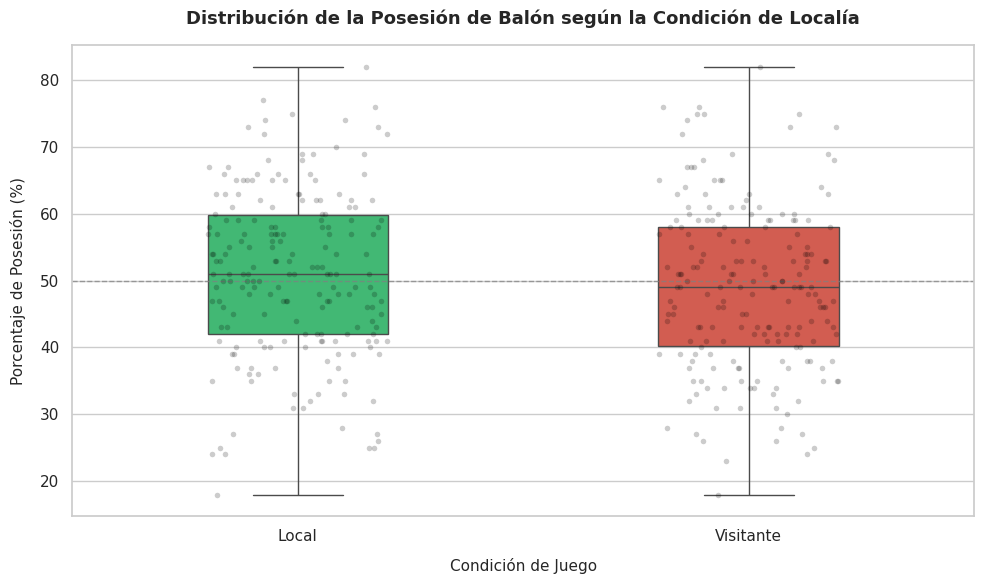

In [7]:
# ==============================================================================
# BLOQUE A: EVALUACIÓN GLOBAL Y DISTRIBUCIÓN DE LA POSESIÓN (LOCAL VS. VISITANTE)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Cuentas y prueba estadística global
mediana_L = df['Posesion_L_num'].median()
mediana_V = df['Posesion_V_num'].median()
pct_mayor_50 = (df['Posesion_L_num'] > 50).mean() * 100

t_stat, p_val = stats.ttest_rel(df['Posesion_L_num'], df['Posesion_V_num'])

print(f"Posesión Promedio Local: {df['Posesion_L_num'].mean():.2f}% | Visitante: {df['Posesion_V_num'].mean():.2f}%")
print(f"Mediana Posesión Local: {mediana_L:.1f}% | Visitante: {mediana_V:.1f}%")
print(f"Partidos con Posesión Local > 50%: {pct_mayor_50:.1f}%")
print(f"Prueba t pareada: t-stat = {t_stat:.4f}, p-value = {p_val:.4f}")

# 2. Visualización Principal (Gráfico 3)
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 6))

df_melted = df.melt(value_vars=['Posesion_L_num', 'Posesion_V_num'], var_name='Condición', value_name='Posesión (%)')
df_melted['Condición'] = df_melted['Condición'].map({'Posesion_L_num': 'Local', 'Posesion_V_num': 'Visitante'})

sns.boxplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    palette=['#2ecc71', '#e74c3c'],
    ax=ax,
    width=0.4
)

sns.stripplot(
    data=df_melted,
    x='Condición',
    y='Posesión (%)',
    color='black',
    alpha=0.2,
    jitter=0.2,
    size=4,
    ax=ax
)

ax.set_title('Distribución de la Posesión de Balón según la Condición de Localía', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Condición de Juego', fontsize=11, labelpad=10)
ax.set_ylabel('Porcentaje de Posesión (%)', fontsize=11, labelpad=10)
ax.axhline(50, color='gray', linestyle='--', linewidth=1, alpha=0.7)

plt.tight_layout()
plt.savefig('grafico3_rol3_localia_pura.png', dpi=300)
plt.show()

**B) Aislamiento por Club y Ranking del "Efecto Empuje" Territorial**

Para evitar enmascarar comportamientos heterogéneos bajo el promedio general, se efectúa una agregación por institución (groupby) que calcula el diferencial de posesión de cada equipo ($\text{Efecto\_Localia\_Pos} = \bar{P}_L - \bar{P}_V$). Esta métrica aísla la influencia real del estadio sobre la propuesta táctica.

El cálculo se complementa con un gráfico de barras horizontales ordenado por diferencial, permitiendo identificar de forma nítida qué equipos transforman su protagonismo al jugar en casa ($+10\%$ a $+14\%$ de tenencia) y en cuáles el modelo táctico prevalece sin importar la sede.

/tmp/ipykernel_3665/3342419833.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


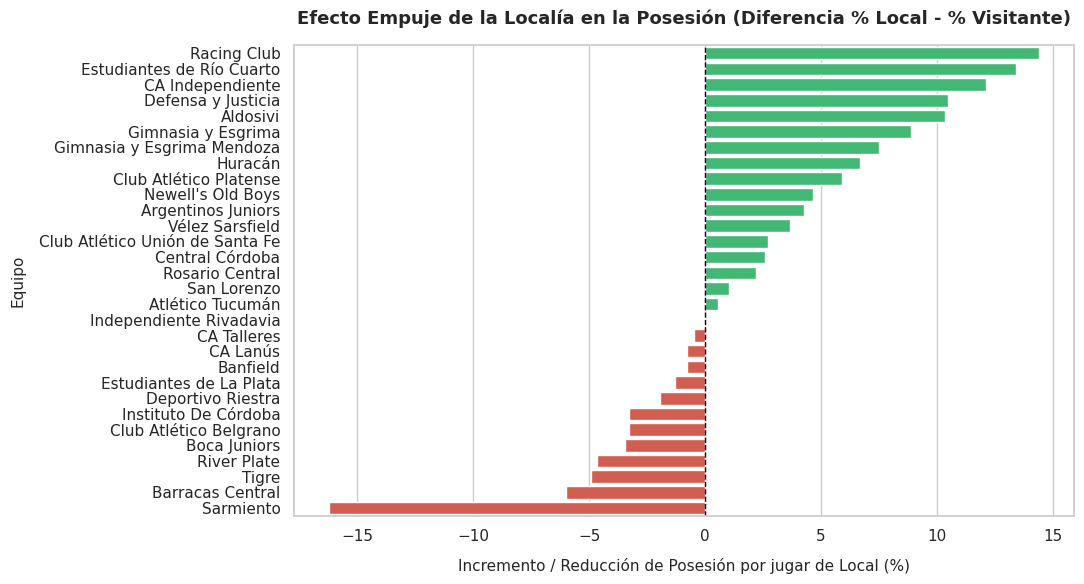

In [10]:
# ==============================================================================
# BLOQUE B: AGREGACIÓN POR CLUB Y RANKING DEL EFECTO EMPUJE EN LA POSESIÓN
# ==============================================================================
# 1. Agregación y cálculo del diferencial por equipo
locales = df.groupby('Local')['Posesion_L_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Local_Prom', 'count': 'PJ_L'})
visitantes = df.groupby('Visitante')['Posesion_V_num'].agg(['mean', 'count']).rename(columns={'mean': 'Pos_Visitante_Prom', 'count': 'PJ_V'})

equipos = locales.join(visitantes)
equipos['Efecto_Localia_Pos'] = equipos['Pos_Local_Prom'] - equipos['Pos_Visitante_Prom']
equipos_ordenados = equipos.sort_values(by='Efecto_Localia_Pos', ascending=False)

# 2. Visualización Auxiliar (Ranking del Efecto Empuje)
top_bottom_efecto = pd.concat([equipos_ordenados]).reset_index()

fig2, ax2 = plt.subplots(figsize=(11, 6))
colors = ['#2ecc71' if val > 0 else '#e74c3c' for val in top_bottom_efecto['Efecto_Localia_Pos']]

sns.barplot(
    data=top_bottom_efecto,
    x='Efecto_Localia_Pos',
    y='Local',
    palette=colors,
    ax=ax2
)

ax2.set_title('Efecto Empuje de la Localía en la Posesión (Diferencia % Local - % Visitante)', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Incremento / Reducción de Posesión por jugar de Local (%)', fontsize=11, labelpad=10)
ax2.set_ylabel('Equipo', fontsize=11, labelpad=10)
ax2.axvline(0, color='black', linestyle='--', linewidth=1)

plt.tight_layout()
plt.savefig('grafico_auxiliar_efecto_empuje.png', dpi=300)
plt.show()

**Conclusiones del Bloque centradas en la Localía**

1. Magnitud del Efecto Campo en la Posesión:

    La localía ejerce un leve predominio en la tenencia del balón, registrando una media del 51.05% de posesión para el local frente al 48.95% para el visitante (un margen promedio de +2.14%). En el 53.1% de los encuentros, el equipo local supera el 50% de tenencia.

2. Inexistencia de un Impacto Absoluto:

    La prueba de hipótesis refleja que el incremento del +2.14% no es estadísticamente determinante (p=0.2388). Esto demuestra que la localía no impone de manera automática el monopolio de la pelota.

3. Variabilidad Táctica por Club ("Efecto Empuje"):

    La influencia del estadio en la posesión varía de acuerdo con el perfil del equipo:

* Localías Potenciadoras del Protagonismo: En clubes como Racing Club (+14.4%), Estudiantes de Río Cuarto (+13.4%) e Independiente (+12.1%), jugar en casa transforma drásticamente la actitud del equipo, haciendo que asuman el control del balón.

* Prevalencia del Estilo sobre el Estadio: En instituciones con modelos de juego fuertemente arraigados, como River Plate (−4.6%) o Boca Juniors (−3.5%), los equipos promedian mayor posesión en condición de visitante que de local, demostrando que su modelo de juego prevalece por encima del factor campo.